In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np 

In [2]:
df=pd.read_csv("../Data/splits/balanced_20k_metadata.csv")

In [10]:
df.columns

Index(['image_name', 'finding_labels', 'follow_up', 'patient_id',
       'patient_age', 'patient_sex', 'view_position', 'image_width',
       'image_height', 'pixel_spacing_x', 'pixel_spacing_y', 'label',
       'binary_label', 'split'],
      dtype='object')

In [7]:
print("Number of Duplicated Rows :",df.duplicated().sum())
print("Number of Patients :",df["patient_id"].nunique())
print("Number of Images :",df["image_name"].nunique())

Number of Duplicated Rows : 0
Number of Patients : 10567
Number of Images : 20000


,image_count
binary_label,
Abnormal,10000
Normal,10000


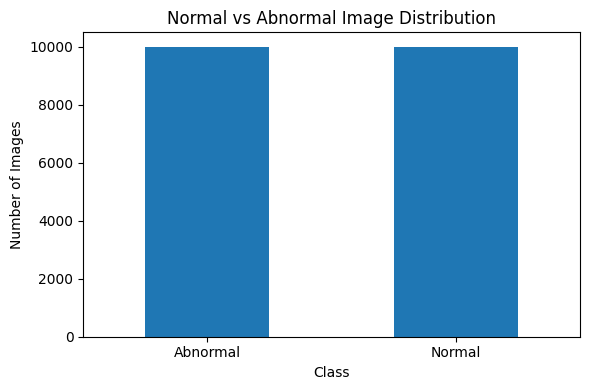

In [13]:
label_counts = df["binary_label"].value_counts()

display(label_counts.to_frame("image_count"))

label_counts.plot(kind="bar", figsize=(6, 4))
plt.title("Normal vs Abnormal Image Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

binary_label,Abnormal,Normal
split,,
test,1500,1500
train,7000,7000
validation,1500,1500


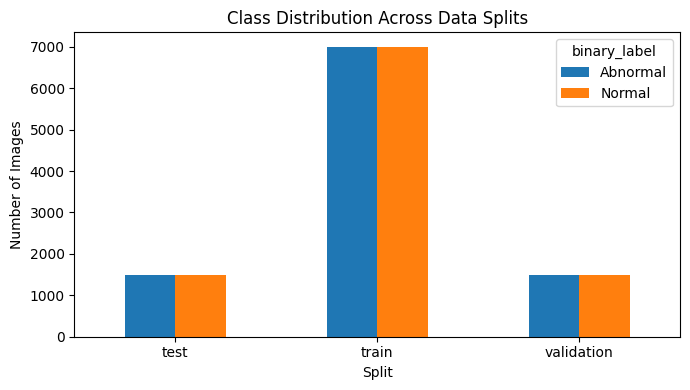

In [14]:
split_counts = pd.crosstab(df["split"], df["binary_label"])

display(split_counts)

split_counts.plot(kind="bar", figsize=(7, 4))
plt.title("Class Distribution Across Data Splits")
plt.xlabel("Split")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,image_count
finding_labels,
Infiltration,3747
Effusion,2770
Atelectasis,2491
Nodule,1587
Mass,1485
Pneumothorax,1391
Consolidation,1264
Pleural_Thickening,993
Cardiomegaly,856


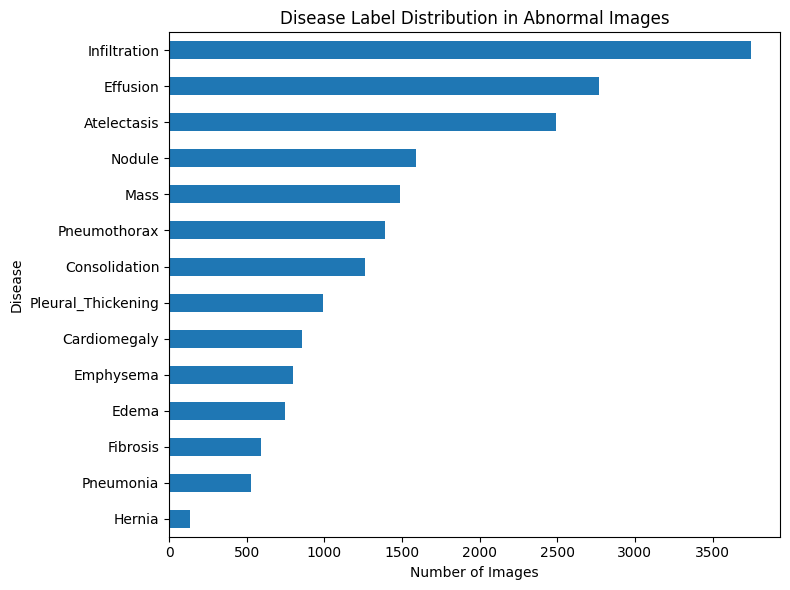

In [15]:
abnormal_df = df[df["binary_label"].astype(str).str.lower() == "abnormal"]

disease_counts = (
    abnormal_df["finding_labels"]
    .dropna()
    .str.split("|")
    .explode()
)

disease_counts = disease_counts[disease_counts != "No Finding"]
disease_counts = disease_counts.value_counts()

display(disease_counts.to_frame("image_count"))

disease_counts.sort_values().plot(
    kind="barh", figsize=(8, 6)
)
plt.title("Disease Label Distribution in Abnormal Images")
plt.xlabel("Number of Images")
plt.ylabel("Disease")
plt.tight_layout()
plt.show()

,image_count
view_position,
PA,11984
AP,8016


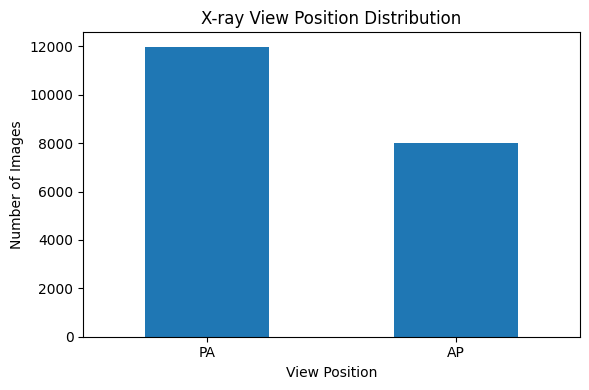

In [16]:
view_counts = df["view_position"].value_counts(dropna=False)

display(view_counts.to_frame("image_count"))

view_counts.plot(kind="bar", figsize=(6, 4))
plt.title("X-ray View Position Distribution")
plt.xlabel("View Position")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

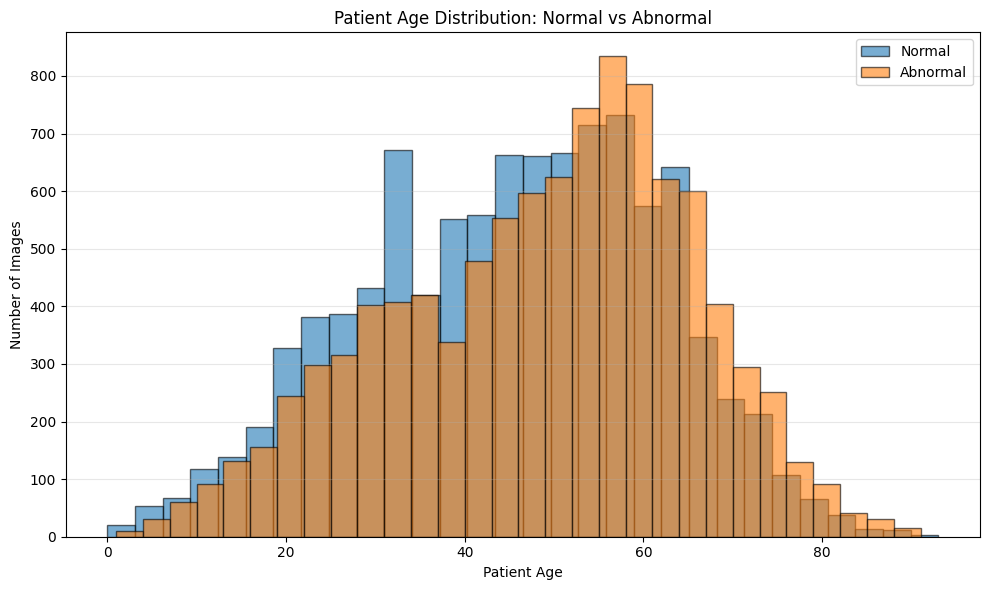

In [11]:
plt.figure(figsize=(10, 6))

plt.hist(
    df.loc[df["label"] == 0, "patient_age"].dropna(),
    bins=30,
    alpha=0.6,
    label="Normal",
    edgecolor="black"
)

plt.hist(
    df.loc[df["label"] == 1, "patient_age"].dropna(),
    bins=30,
    alpha=0.6,
    label="Abnormal",
    edgecolor="black"
)

plt.xlabel("Patient Age")
plt.ylabel("Number of Images")
plt.title("Patient Age Distribution: Normal vs Abnormal")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
df.groupby("label")["patient_age"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,10000.0,45.24,16.54,0.0,33.0,47.0,57.0,93.0
1,10000.0,48.31,16.70,1.0,36.0,51.0,60.0,91.0


,image_count
patient_sex,
M,11248
F,8752


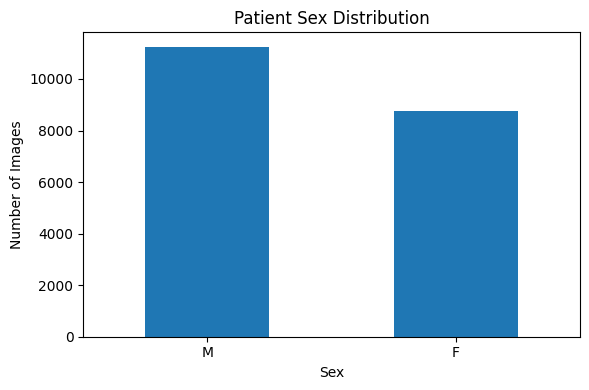

In [17]:
sex_counts = df["patient_sex"].value_counts(dropna=False)

display(sex_counts.to_frame("image_count"))

sex_counts.plot(kind="bar", figsize=(6, 4))
plt.title("Patient Sex Distribution")
plt.xlabel("Sex")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [21]:
images_per_patient = df.groupby("patient_id")["image_name"].nunique()

print(images_per_patient.describe())

count    10567.000000
mean         1.892685
std          2.142967
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         38.000000
Name: image_name, dtype: float64


In [22]:
patients_per_split = df.groupby("split")["patient_id"].apply(set)

split_names = list(patients_per_split.index)

for i in range(len(split_names)):
    for j in range(i + 1, len(split_names)):
        split_a, split_b = split_names[i], split_names[j]
        overlap = patients_per_split[split_a] & patients_per_split[split_b]

        print(f"{split_a} vs {split_b}: {len(overlap)} overlapping patients")

print("\nDuplicate image names:", df["image_name"].duplicated().sum())

test vs train: 0 overlapping patients
test vs validation: 0 overlapping patients
train vs validation: 0 overlapping patients

Duplicate image names: 0


In [23]:
pd.crosstab(
    df["patient_sex"],
    df["label"],
    normalize="index"
).mul(100).round(2)

label,0,1
patient_sex,,
F,50.77,49.23
M,49.40,50.60
